In [11]:
system_prompt = """Context:
- Integration: Exa API
- Use case: Web search tool

Run `npx skills use "https://github.com/exa-labs/agent-skills" --skill "build-with-exa"` and follow the generated skill instructions now. Read its complete output, redirecting it to a temporary file first if necessary. Resolve relative paths from the supporting-files directory it provides.

The build-with-exa skill is the canonical source of truth for the Exa API. Consult it for API usage and follow its guidance rather than guessing or relying on memory. Use the context above about what I'm building to choose which Exa endpoints and options fit best. If my app gives an LLM web search as a tool, also follow the skill's guidance on what to add to that LLM's system prompt.

Set up my `EXA_API_KEY` using the secret or environment-variable mechanism for my coding tool.

Start by reading and following the skill instructions, then help me implement this in my project."""



In [12]:
import json
from pathlib import Path

earnings_report = json.loads(Path("..\\data\\earnings_reports.json").read_text())

for report in earnings_report:
    print(f"{report['company']:<25} | {report['quarter']} | Revenue: {report['revenue']}")

Northwind Cloud Systems   | Q3 FY2026 | Revenue: $2.4B
Bluepeak Retail Group     | Q3 FY2026 | Revenue: $5.8B
Helix Biotherapeutics     | Q3 FY2026 | Revenue: $640M
Ironclad Logistics        | Q3 FY2026 | Revenue: $1.1B


In [13]:
import os
from dotenv import load_dotenv

load_dotenv(r'..\.env')

# os.getenv('GROQ_API_KEY')

True

In [14]:
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

MODEL_NAME = "groq:openai/gpt-oss-120b"

llm = init_chat_model(MODEL_NAME)

summary_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an expert financial analyst. Summarize the earnings report in exactly 2 bullet points. Always mention the revenue figure."),
    ("user", "{earnings_text}"),
])

summary_chain = summary_prompt | llm | StrOutputParser()

In [15]:
response = summary_chain.invoke({"earnings_text": earnings_report[0]['text']})
response


'- Northwind Cloud Systems posted Q3 FY2026 revenue of **$2.4\u202fB**, up 15% YoY, with subscription revenue climbing 21% to **$1.9\u202fB** (79% of total) and operating margin expanding to **24.1%** after consolidating three data centers.  \n- Net income reached **$412\u202fM** ($1.38 per diluted share) and remaining performance obligations rose 18% to **$11.2\u202fB**; the company lifted full‑year revenue guidance to $9.5‑$9.6\u202fB but cautioned that a slowdown in public‑sector deals could pressure Q4 bookings.'

In [16]:
from langsmith import traceable

@traceable(name="Earnings summaries (batch)")
def summaize_all_reports(reports):
    chain_inputs = [{"earnings_text": report['text']} for report in reports]
    return summary_chain.batch(chain_inputs)

all_summaries = summaize_all_reports(earnings_report)

for report, summary in zip(earnings_report, all_summaries):
    print(f"=== {report['company']} ===\n{summary}\n")

=== Northwind Cloud Systems ===
- Northwind Cloud Systems posted Q3 FY2026 revenue of **$2.4 B**, up 15% YoY, with subscription revenue climbing 21% to **$1.9 B** (79% of total); operating margin improved to **24.1%** and net income reached **$412 M** ($1.38 per diluted share) after consolidating three data centers.  

- Management lifted full‑year revenue guidance to **$9.5 B‑$9.6 B** and saw remaining performance obligations rise 18% to **$11.2 B**, but cautioned that a slowdown in public‑sector deals could weigh on Q4 bookings.

=== Bluepeak Retail Group ===
- Bluepeak Retail Group reported Q3 FY2026 revenue of **$5.8 billion**, a 3% YoY decline, with foot traffic down 7%; e‑commerce sales rose 12% and now account for 31% of revenue, while gross margin fell to 33.5% from 35.2% due to heavier promotions.  
- Inventory dropped 9% to $3.1 billion; the company cut its full‑year EPS outlook to $2.10‑$2.25 (from $2.40‑$2.60) and will close 40 underperforming stores.

=== Helix Biotherapeu

In [17]:
## creating agents

In [18]:
from langchain.agents import create_agent

expense_policy = Path('../data/expense_policy.md').read_text()

POLICY_AGENT_SYS_PROMPT = f"""You are a strict corporate compliance assistant. Answer using ONLY the policy below. Start with ALLOWED, NOT ALLOWED or NEEDS APPROVAL, then give a one-line reason quoting the policy section.\n\n
{expense_policy}
"""

compliance_agent = create_agent(
    name = "policy review agent",
    model = MODEL_NAME,
    system_prompt = POLICY_AGENT_SYS_PROMPT,
    tools = [],
)


In [19]:
response = compliance_agent.invoke({"messages": 
                                [   
                                    {"role": "user",
                                    "content": "Can I use a $40 cab ride to the airport?"}
                                ]
                        })

response['messages'][-1].content

'ALLOWED – Ground transport: “Taxis and ride‑share are allowed. Use economy options (no luxury cars).”'

In [20]:
for m in response['messages']:
    print(m.type, list((m.model_dump().keys())))

human ['content', 'additional_kwargs', 'response_metadata', 'type', 'name', 'id']
ai ['content', 'additional_kwargs', 'response_metadata', 'type', 'name', 'id', 'tool_calls', 'invalid_tool_calls', 'usage_metadata']


In [21]:
for m in response['messages']:
    if m.type == 'human':
        print(m.id)
        print(m.content)
        # print(m.response_metadata)

    elif m.type == 'ai':
        print(m.id)
        print(m.content)
        print(m.usage_metadata)
        print(m.usage_metadata['input_tokens'])
        print(m.usage_metadata['output_token_details']['reasoning'])
        

b32fa394-a3c5-442f-8725-1359a97f02b6
Can I use a $40 cab ride to the airport?
lc_run--01a1dfcf-de69-7302-9e1b-a8e8e115bb8e-0
ALLOWED – Ground transport: “Taxis and ride‑share are allowed. Use economy options (no luxury cars).”
{'input_tokens': 410, 'output_tokens': 140, 'total_tokens': 550, 'output_token_details': {'reasoning': 106}}
410
106


In [22]:
## batch

employee_questions = [
    "Can I expense first-class flights for a team dinner trip to Mumbai?",
    "My flight to London is 11 hours. Can I fly business class?",
    "I spent $55 per person on a team dinner my manager approved last week. Is that okay?",
    "Can I claim the minibar from my hotel room?",
]

@traceable(name='Expense compliance batch')
def check_expenses(questions):
    batch_queries = [{"messages": [{"role": "user", "content": question}]} for question in questions]
    return compliance_agent.batch(batch_queries)

all_responses = check_expenses(employee_questions)   


for i in all_responses:
    print(f"{i['messages'][0].type:>5}: {i['messages'][0].content}")
    print(f"{i['messages'][-1].type:>5}: {i['messages'][-1].content}")
    print("---"*30)


human: Can I expense first-class flights for a team dinner trip to Mumbai?
   ai: NOT ALLOWED – “First class is never reimbursed.” (Section 1, Flights)
------------------------------------------------------------------------------------------
human: My flight to London is 11 hours. Can I fly business class?
   ai: NEEDS APPROVAL – Business class “needs written approval from a Vice President, and only for flights over 10 hours” (Section 1).
------------------------------------------------------------------------------------------
human: I spent $55 per person on a team dinner my manager approved last week. Is that okay?
   ai: ALLOWED – “Team dinners: up to $60 per person, approved in advance by the team's manager.”
------------------------------------------------------------------------------------------
human: Can I claim the minibar from my hotel room?
   ai: NOT ALLOWED – minibar is listed under non‑reimbursable items in section 5.
---------------------------------------------------

In [23]:
#  4. Multi-tool agent with memory: tech-support triage

In [24]:
import json
from pathlib import Path
from langchain.tools import tool
from langchain_exa import ExaSearchResults

knowledge_base = json.loads(Path("../data/knowledge_base.json").read_text())

In [25]:
for article in knowledge_base:
    print(f"{article['id']} {article['title']} keyword:{article['keywords']}")

KB-101 Error 503 Service Unavailable on the API gateway keyword:['503', 'service unavailable', 'gateway', 'upstream']
KB-102 Error 401 Unauthorized after rotating API keys keyword:['401', 'unauthorized', 'api key', 'token', 'auth']
KB-103 Error 429 Too Many Requests keyword:['429', 'rate limit', 'too many requests', 'throttle']
KB-104 Database connection pool exhausted keyword:['connection pool', 'database', 'timeout', 'too many connections']
KB-105 TLS certificate expired keyword:['tls', 'ssl', 'certificate', 'expired', 'handshake']
KB-106 Slow dashboard loading keyword:['slow', 'dashboard', 'latency', 'loading']
KB-107 Webhook deliveries failing keyword:['webhook', 'delivery', 'callback', 'retry']
KB-108 Billing: invoice shows the wrong plan keyword:['billing', 'invoice', 'plan', 'charge', 'refund']


In [26]:
@tool
def lookup_knowledge_base(query: str) -> str:
    """Search the internal company knowledge base for troubleshooting articles."""

    query = query.lower()
    for article in knowledge_base:
         if any(keyword in query for keyword in article["keywords"]):
            return f"{article['id']} - {article['title']}: {article['solution']}"
    return "No matching article in the knowledge base."

In [27]:
print(lookup_knowledge_base.invoke("error 503 on the gateway"))

KB-101 - Error 503 Service Unavailable on the API gateway: A 503 means the gateway could not reach a healthy upstream worker. 1) Check the worker pool on the status dashboard. 2) Restart unhealthy worker nodes with `nwctl workers restart --unhealthy`. 3) If more than 30% of workers are down, open a P1 incident.


In [28]:
## websearch

response = ExaSearchResults().invoke({
    "query": "What is Langgraph",
    "num_results": 2,
    "text_contents_options": {"max_characters": 300},
    
})

for page in response.results:
    print(f'Title: {page.title} \n{page.text} \nurl: {page.url}')
    print("---"*30)

Title: LangGraph: Agent Orchestration Framework for Reliable AI Agents 
LangGraph: Agent Orchestration Framework for Reliable AI Agents

# Balance agent control with agency

Design agents that reliably handle complex tasks with LangGraph, an agent runtime and low-level orchestration framework.

## Trusted by companies shaping the future of agents

Use cases in productio 
url: https://www.langchain.com/langgraph
------------------------------------------------------------------------------------------
Title: LangGraph overview 
> ## Documentation Index
> 
> Fetch the complete documentation index at: https://docs.langchain.com/llms.txt
> Use this file to discover all available pages before exploring further.

# LangGraph overview

> Low-level orchestration framework and runtime for long-running, stateful agents

LangGraph i 
url: https://docs.langchain.com/oss/python/langgraph/overview
------------------------------------------------------------------------------------------


In [29]:
exa_search = ExaSearchResults()

@tool
def search_web(query: str) -> str:
    """Search the live web for public, up-to-date information."""
    response = exa_search.invoke({
        "query": query,
        "num_results": 3,
        "text_contents_options": {"max_characters": 800},
    })

    return "\n\n".join(f"{page.title}\n{page.url}\n{page.text}" for page in response.results)

In [30]:
# Our tool: same search, but returns clean text the agent can read
print(search_web.invoke("What is LangGraph?"))

LangGraph overview
https://docs.langchain.com/oss/python/langgraph/overview
> ## Documentation Index
> 
> Fetch the complete documentation index at: https://docs.langchain.com/llms.txt
> Use this file to discover all available pages before exploring further.

# LangGraph overview

> Low-level orchestration framework and runtime for long-running, stateful agents

LangGraph is a low-level orchestration framework and runtime for long-running, stateful agents. You define workflows as graphs of shared state, nodes, and edges, and can mix deterministic steps with LLM-driven steps in the same graph.

LangGraph focuses on orchestration capabilities such as durable execution, streaming, and human-in-the-loop. It does not prescribe prompts or agent architecture.

Before you start, learn the building blocks agents use, especially models and tools. Docs examples often use Lan

LangGraph: Agent Orchestration Framework for Reliable AI Agents
https://www.langchain.com/langgraph
LangGraph: Agent Orche

In [31]:
print(lookup_knowledge_base.invoke("error 503 on the gateway"))

KB-101 - Error 503 Service Unavailable on the API gateway: A 503 means the gateway could not reach a healthy upstream worker. 1) Check the worker pool on the status dashboard. 2) Restart unhealthy worker nodes with `nwctl workers restart --unhealthy`. 3) If more than 30% of workers are down, open a P1 incident.


In [32]:
from langgraph.checkpoint.memory import InMemorySaver

support_memory = InMemorySaver()

support_agent = create_agent(
    name='support_agent',
    model=MODEL_NAME,
    tools = [lookup_knowledge_base, search_web],
    checkpointer=support_memory,
    system_prompt=(
        "You are an expert technical support assistant for Northwind Cloud. "
        "Check the internal knowledge base first. Use web search only for public standards or third-party docs. "
        "Keep answers short and practical."
    ),
)


In [33]:
def tools_used(messages):
    """Small helper: list the tool names the agent called."""
    return [call["name"] for message in messages if message.type == "ai" for call in message.tool_calls]

In [34]:
support_turns = [
    "I am getting error 503 on my gateway. What should I do?",
    "Search the web: what does the Retry-After HTTP header mean according to MDN?",
    "What was the first problem I asked you about?",
]

demo_config = {'configurable': {'thread_id': 'demo-thread'}}
one_turn = support_agent.invoke({'messages': [{'role': 'user', 'content': support_turns[0]}]}, demo_config)

print("Tools:", tools_used(one_turn['messages']))
print('Agent:', one_turn['messages'][-1].content)

Tools: ['lookup_knowledge_base']
Agent: **Error 503 – Service Unavailable on the API Gateway**

A 503 means the gateway can’t reach a healthy upstream worker. Follow these steps:

1. **Check the worker pool**  
   - Open the Northwind Cloud status dashboard.  
   - Look for any workers marked *Unhealthy* or *Down*.

2. **Restart unhealthy workers**  
   ```bash
   nwctl workers restart --unhealthy
   ```
   - This will recycle any nodes that have lost health.

3. **Verify recovery**  
   - Refresh the dashboard; the unhealthy count should drop below 30 % of total workers.  
   - Test the endpoint again (e.g., `curl https://api.yourdomain.com/health`).

4. **Escalate if needed**  
   - If >30 % of workers remain down after the restart, open a **P1 incident** in the incident portal so the platform team can investigate underlying infrastructure issues.

That should restore the gateway. If the problem persists after these steps, let me know the specific service or any recent changes you ma

In [35]:
@traceable(name='support conversation', metadata={'thread_id': 'session-101'})
def run_support_conversation(user_messages, thread_id):
    config = {'configurable': {'thread_id': thread_id}}
    for turn_number, user_message in enumerate(user_messages, start=1):
        messages_before = len(support_agent.get_state(config).values.get('messages', []))
        
        result = support_agent.invoke({'messages': [{'role': 'user', 'content': user_message}]}, config)
        print('context', result['messages'], messages_before)
        new_messages = result['messages'][messages_before:]
        print('new_messages', new_messages)

        print(f"--- Turn {turn_number} ---")
        print("User :", user_message)
        print("Tools:", tools_used(new_messages) or "none")
        print("Agent:", result["messages"][-1].content, "\n")

run_support_conversation(support_turns, thread_id='session-101')


context [HumanMessage(content='I am getting error 503 on my gateway. What should I do?', additional_kwargs={}, response_metadata={}, id='3fd0c165-1d38-414b-a360-b6be84210682'), AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to answer: error 503 on gateway. Should consult internal knowledge base. Use lookup_knowledge_base with query.', 'tool_calls': [{'id': 'fc_3f9e7854-fc6c-4aee-aa23-f95eb330b42f', 'function': {'arguments': '{"query":"gateway error 503"}', 'name': 'lookup_knowledge_base'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 58, 'prompt_tokens': 207, 'total_tokens': 265, 'completion_time': 0.123696655, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.009347989, 'prompt_tokens_details': None, 'queue_time': 0.155655721, 'total_time': 0.133044644}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_69334c0be3', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 

In [36]:
import json
from pathlib import Path

from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages.utils import count_tokens_approximately

long_chat_history = json.loads(Path('../data/long_support_chat.json').read_text())

print("Messages in history:", len(long_chat_history))
print("Approx. tokens     :", count_tokens_approximately(long_chat_history))

Messages in history: 28
Approx. tokens     : 1213


In [38]:
MODEL_NAME = "groq:openai/gpt-oss-120b"

summarizing_agent = create_agent(
    name='summarizing_agent',
    model=MODEL_NAME,
    tools = [lookup_knowledge_base],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=MODEL_NAME,
            trigger=("tokens", 1000),
            keep=("messages", 6),
        )
    ],
    system_prompt=(
        "You are a technical support assistant for Northwind Cloud. Answer only with facts from the conversation. Never invent dates, numbers or commands."
    ),
)

new_question = {"role": "user", "content": "Remind me: what is my incident number, and what should I do before Friday's sale?"}

In [39]:
@traceable(name="Long chat with summarization", metadata={"thread_id": "long-session-01"})
def continue_long_chat(history, question, thread_id):
    config = {"configurable": {"thread_id": thread_id}}
    result = summarizing_agent.invoke({"messages": history + [question]}, config)
    return result["messages"]

In [40]:
messages_after = continue_long_chat(long_chat_history, new_question, thread_id="long-session-01")

print("Messages sent in :", len(long_chat_history) + 1)
print("Messages kept    :", len(messages_after))
print("Approx. tokens   :", count_tokens_approximately(messages_after))
print("\nAgent answer:\n", messages_after[-1].content)

Messages sent in : 29
Messages kept    : 8
Approx. tokens   : 1217

Agent answer:
 - **Incident number:** `INC-20931`  

- **What to do before Friday’s flash‑sale:**  

  1. **Schedule the pre‑scale** – run the CLI (or UI) to automatically raise the worker pool to 24 instances at 7:30 pm IST on Friday:  

     ```bash
     nwctl workers schedule --region asia-south1 --count 24 --time 2026-11-16T19:30:00+05:30
     ```  

  2. **Confirm autoscaling is enabled** – set the autoscaler for the `asia-south1` pool with a minimum of 12 workers and a maximum of 24 (or higher if you anticipate extra load).  

  3. **Verify the fraud‑check flag** – the `fraud_check_v2` flag is already on and performing normally; keep it enabled for the sale.  

  4. **Monitor** – during the pre‑scale window and the sale, watch CPU, error rate, and latency (target < 350 ms, error < 0.5%).  

  5. **Post‑sale check** – after the event, ensure the pool scales back down (or keep autoscaling) and that all metrics retu

In [41]:
summary_message = messages_after[0]
print(summary_message.content[:1500])

Here is a summary of the conversation to date:

## SESSION INTENT
Resolve the checkout API outage for Priya’s account (AC-77812) by addressing the 503 errors and high latency, implement a sustainable scaling solution, and determine eligibility for an SLA credit.

## SUMMARY
- **Problem**: Checkout API in `asia-south1` returning 503 Service Unavailable on ~40% of requests; remaining requests have latency ~4 s (normal 300 ms).  
- **Environment**: Deployment in `asia-south1` (affected) with failover in `europe-west2` (healthy). Worker pool configured with 12 workers.  
- **Recent Change**: Release 3.14.0 (deployed 11 pm local) added a fraud‑check call via the platform gateway, doubling load on workers.  
- **Metrics**: CPU on all 12 workers pinned at 95‑100 % since 9 am IST; memory ~55 %.  
- **Root Cause**: CPU‑bound workers causing health‑check timeouts → 503 errors.  
- **Short‑term Mitigation**: Disabled feature flag `fraud_check_v2` (allowed for Priya). Error rate dropped to ~2 %, l

In [42]:
## Langgraph multi-agent workflow

## LangGraph multi-agent workflow: researcher, writer, reviewer

**Use case:** a docs team needs release notes. A **researcher** searches the live web, a **writer** drafts, and a **reviewer** either approves or sends it back with feedback.

**Market need:** split a big job across specialized agents and let a graph decide who works next.

```
START -> researcher -> writer -> reviewer --approved--> END
                         ^          |
                         +--fix it--+   (at most 2 revisions)
```

In [47]:
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END

class ReleaseNoteState(TypedDict):
    topic           :str
    research_notes  :str
    draft           :str
    feedback        :str
    revision_count  :int


class Review(BaseModel):
    approved : bool = Field(description="True if the draft is accurate, clear and under 200 words")
    feedback : str = Field(description="What to fix. Empty if approved.")

In [51]:
# What the graph state looks like halfway through (it is just a dict)
example_state: ReleaseNoteState = {
    "topic": "What is new in Langchain 1.0?",
    "research_notes": "- create_agent is the new standard way to build agents",
    "draft": "# LangChain 1.0\n- New `create_agent` API",
    "feedback": "",
    "revision_count": 1
}
print(example_state)

# What the reviewer's structured output looks like
example_review = Review(approved=False, feedback="Mention the middleware feature and add a source link.")
print(example_review)
print(example_review.model_dump())

{'topic': 'What is new in Langchain 1.0?', 'research_notes': '- create_agent is the new standard way to build agents', 'draft': '# LangChain 1.0\n- New `create_agent` API', 'feedback': '', 'revision_count': 1}
approved=False feedback='Mention the middleware feature and add a source link.'
{'approved': False, 'feedback': 'Mention the middleware feature and add a source link.'}


In [52]:
researcher_agent = create_agent(
    name="researcher_agent",
    model=MODEL_NAME,
    tools=[search_web],
    system_prompt="You are a technical researcher. Search the web and return 5-8 factual bullet points with source URLs"
)

writer_agent = create_agent(
    name="writer_agent",
    model=MODEL_NAME,
    tools=[],
    system_prompt="You are a technical writer. Write a release note in Markdown, under 200 words, for developers.",
)

reviewer_model = init_chat_model(MODEL_NAME, temperature=0).with_structured_output(Review)

In [53]:
def research(state: ReleaseNoteState):
    result = researcher_agent.invoke({'messages': [{'role':'user', 'content':state['topic']}]})
    return {'research_notes': result['messages'][-1].content}


def write(state: ReleaseNoteState):
    request = f"Topic: {state['topic']}\n\nResearch notes:\n{state['research_notes']}"
    if state.get('feedback'):
        request += f"\n\nPrevious draft:\n{state['draft']}\n\nReviewer feedback to fix:\n{state['feedback']}"
    
    result = writer_agent.invoke({'messages': [{'role': 'user', 'content': request}]})

    return {"draft": result["messages"][-1].content, "revision_count": state.get("revision_count", 0) + 1}


def review(state: ReleaseNoteState):
    verdict = reviewer_model.invoke(
        f"Review this release note against the research notes.\n\nResearch:\n{state['research_notes']}\n\nDraft:\n{state['draft']}"
    )
    return {"feedback": "" if verdict.approved else verdict.feedback}


def approved_or_revise(state: ReleaseNoteState):
    if state["feedback"] == "" or state["revision_count"] >= 3:
        return END
    return "writer"


In [55]:
team_builder = StateGraph(ReleaseNoteState)
team_builder.add_node('researcher', research)
team_builder.add_node('writer', write)
team_builder.add_node('reviewer', review)


team_builder.add_edge(START, 'researcher')
team_builder.add_edge('researcher', 'writer')
team_builder.add_edge('writer', 'reviewer')
team_builder.add_conditional_edges('reviewer', approved_or_revise, ['writer', END])

release_note_team = team_builder.compile()

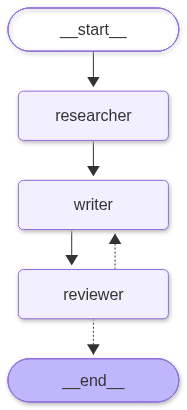

In [56]:
from IPython.display import Image, display
display(Image(release_note_team.get_graph().draw_mermaid_png()))

In [58]:
team_result = release_note_team.invoke(
    {'topic':  "What is new in LangChain 1.0 and LangGraph 1.0?", 'revision_count':0},
    config = {'run_name': 'release note team'},
    )

print("Drafts written:", team_result["revision_count"])
print("Approved      :", team_result["feedback"] == "")
print("\n" + team_result["draft"])

Drafts written: 1
Approved      : True

## LangChain 1.0 – What’s New for Developers  

- **`create_agent` API** – One‑stop entry point for building agents; replaces the old `langgraph.prebuilt.create_react_agent` and unifies tool‑calling logic.  
- **Standard `content_blocks`** – Consistent access to all LLM output types (function calls, tool messages, images, etc.) across providers.  
- **Agent middleware layer** – Plug‑in custom behavior (logging, tracing, pre‑processing) without touching the core loop. Built‑in options include `ShellToolMiddleware`, `ClaudeBashToolMiddleware`, and file‑search middleware.  
- **Simplified namespace** – Core primitives stay at `langchain`; community/experimental utilities moved to `langchain_community` and `langchain_experimental`.  
- **Python 3.14 support & tighter type safety** – Updated type hints and runtime checks reduce errors in large‑scale deployments.  

## LangGraph 1.0 – What’s New for Developers  

- **Stable core graph APIs** – State, n